# Clasificación de planos ecográficos fetales



## 0. Configuración del entorno (Colab)

In [ ]:

!pip install -q imagehash

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#@title Librerias
import os
import random
import hashlib
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import figure
from PIL import Image
import imagehash
from joblib import Parallel, delayed
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [ ]:
# Ruta base del dataset en Google Drive -> Lista de opciones para trabajo colaborativo
POSIBLES_RUTAS = [
    Path('/content/drive/MyDrive/IA2/Proyecto/dataset'),
    Path('/content/drive/MyDrive/dataset'),
    Path('/content/drive/MyDrive/Proyecto/dataset'),
    Path('/content/dataset'),   # dataset descargado con gdown (ver README, opcion B/C)
    # Agrega aquí las rutas de tus otros colaboradores:
    # Path('/content/drive/MyDrive/otra_ruta_colaborador'),
]
DATASET_DIR = None
for ruta in POSIBLES_RUTAS:
    if ruta.exists():
        DATASET_DIR = ruta
        print(f"Dataset detectado y cargado desde: {DATASET_DIR}")
        break

if DATASET_DIR is None:
    # Por defecto si ninguna existe (puedes ajustar a tu ruta principal)
    DATASET_DIR = POSIBLES_RUTAS[0]
    print(f"Advertencia: No se encontró ninguna ruta existente. Usando por defecto: {DATASET_DIR}")

CSV_PATH = DATASET_DIR / 'FETAL_PLANES_DB_data.csv'
image_dir = DATASET_DIR / 'Images'

Dataset detectado y cargado desde: /content/drive/MyDrive/Proyecto/dataset


# Parte 1. Exploración de datos (EDA)

## Carga del dataset

In [ ]:
#Ruta de del archivo .csv
df =  pd.read_csv(CSV_PATH, delimiter=';')
print(df.head())

# Creacion de una columna con la ruta absoluta de cada imagen, añadiendo la extension .png
df['filepath'] = df['Image_name'].apply(lambda x: str(image_dir / (x + '.png')))

#vista previa para comprobar si el enlace es correcto
print(df[['filepath', 'Plane']].head())

                    Image_name  Patient_num  Plane  Brain_plane Operator  \
0  Patient00001_Plane1_1_of_15            1  Other  Not A Brain    Other   
1  Patient00001_Plane1_2_of_15            1  Other  Not A Brain    Other   
2  Patient00001_Plane1_3_of_15            1  Other  Not A Brain    Other   
3  Patient00001_Plane1_4_of_15            1  Other  Not A Brain    Other   
4  Patient00001_Plane1_5_of_15            1  Other  Not A Brain    Other   

  US_Machine  Train   
0      Aloka       1  
1      Aloka       1  
2      Aloka       1  
3      Aloka       1  
4      Aloka       1  
                                            filepath  Plane
0  /content/drive/MyDrive/Proyecto/dataset/Images...  Other
1  /content/drive/MyDrive/Proyecto/dataset/Images...  Other
2  /content/drive/MyDrive/Proyecto/dataset/Images...  Other
3  /content/drive/MyDrive/Proyecto/dataset/Images...  Other
4  /content/drive/MyDrive/Proyecto/dataset/Images...  Other


## Asignación de las variables de etiquetas e imágenes y copia del dataset

In [ ]:
#Asignamiento de los valores de la variable clase (imagenes) junto con sus clases
X = df['filepath'].values
y = df['Plane'].values

#Copia del dataset
df_copy = df.copy()

## Distribución de clases

/tmp/ipykernel_1765/1304519463.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_copy,x='Plane', palette='viridis',order=df['Plane'].value_counts().index)


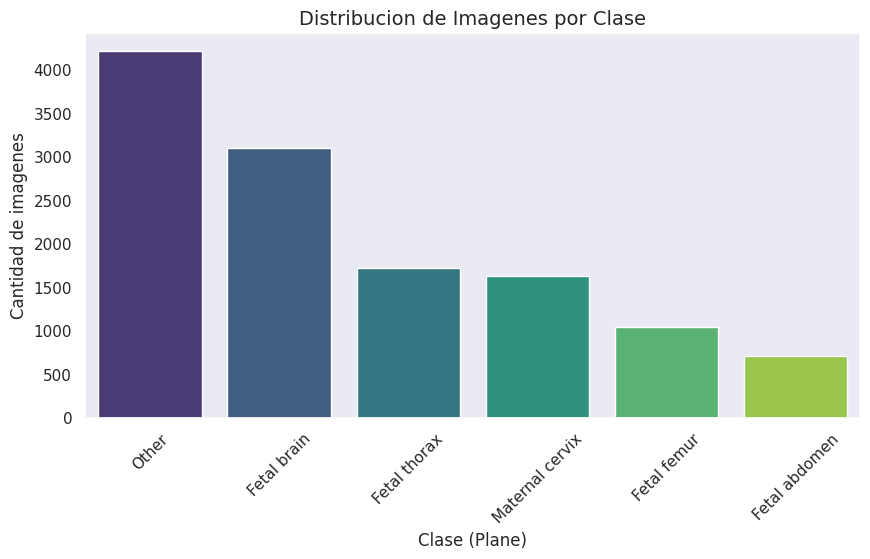

In [ ]:

#Grafica de Distribucion de clases
sns.set_theme(style="dark")

plt.figure(figsize=(10,5))
sns.countplot(data=df_copy,x='Plane', palette='viridis',order=df['Plane'].value_counts().index)
plt.title('Distribucion de Imagenes por Clase', fontsize=14)
plt.xlabel('Clase (Plane)')
plt.ylabel('Cantidad de imagenes')
plt.xticks(rotation=45)
plt.show()

## Muestra aleatoria de imágenes

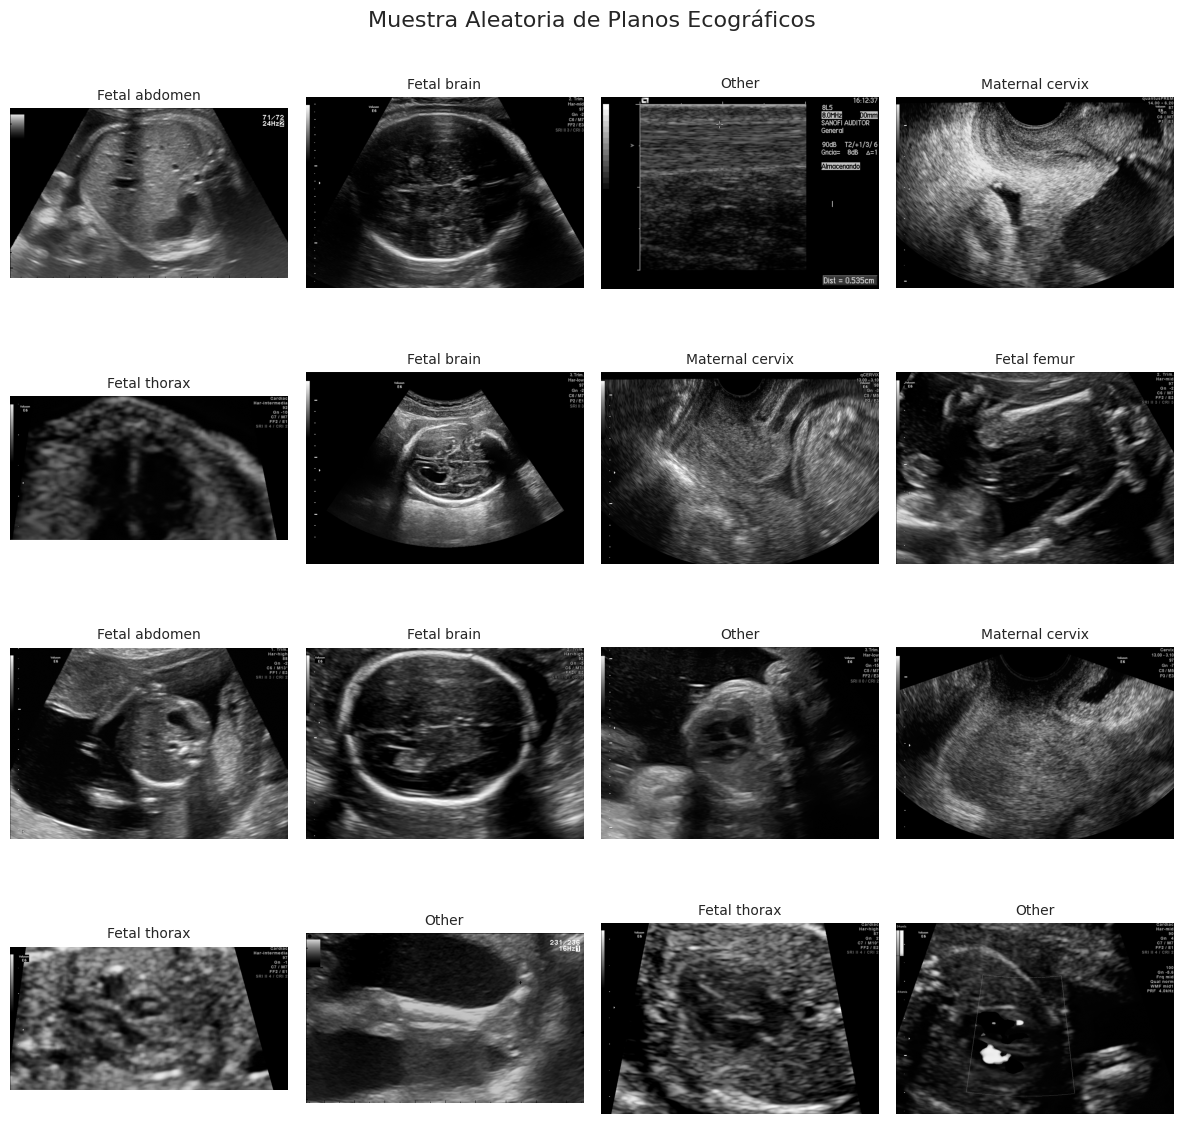

In [ ]:
# Seleccionar 16 imágenes aleatorias del DataFrame
sample_df = df_copy.sample(16)

plt.figure(figsize=(12, 12))
for i, (idx, row) in enumerate(sample_df.iterrows()):
    # Cargar la imagen en escala de grises
    img = cv2.imread(row['filepath'], cv2.IMREAD_GRAYSCALE)

    plt.subplot(4, 4, i + 1)
    if img is not None:
        plt.imshow(img, cmap='gray')
    plt.title(row['Plane'], fontsize=10)
    plt.axis('off')

plt.suptitle('Muestra Aleatoria de Planos Ecográficos', fontsize=16)
plt.tight_layout()
plt.show()

## Métricas por imagen: brillo, contraste y nitidez

In [ ]:
def extraer_metricas(filepath):
  #IMREAD_REDUCED_GRAYSCALE_2 carga la imagen ya a la mitad de la resolucion
  img = cv2.imread(filepath, cv2.IMREAD_REDUCED_GRAYSCALE_2)
  if img is None:
    return None, None, None
  brillo = np.mean(img)
  contraste = np.std(img)
  nitidez = cv2.Laplacian(img, cv2.CV_64F).var()
  return brillo, contraste, nitidez
num_cores =-1
filepaths = df_copy['filepath'].tolist()
print(f'Inicializando procesamiento en paralelo de las imagenes.---')
resultados = Parallel(n_jobs=num_cores, batch_size=64)(
    delayed(extraer_metricas)(fp) for fp in tqdm(filepaths, desc='Procesando imagenes'))
print('Proceso completado')
metrics_df = pd.DataFrame(resultados, columns=['brillo', 'contraste', 'nitidez'])
metrics_df.index = df.index

df_copy[['brillo', 'contraste', 'nitidez']] = metrics_df
df_copy.dropna

Inicializando procesamiento en paralelo de las imagenes.---


Procesando imagenes:  23%|██▎       | 2820/12400 [17:30<1:15:53,  2.10it/s]

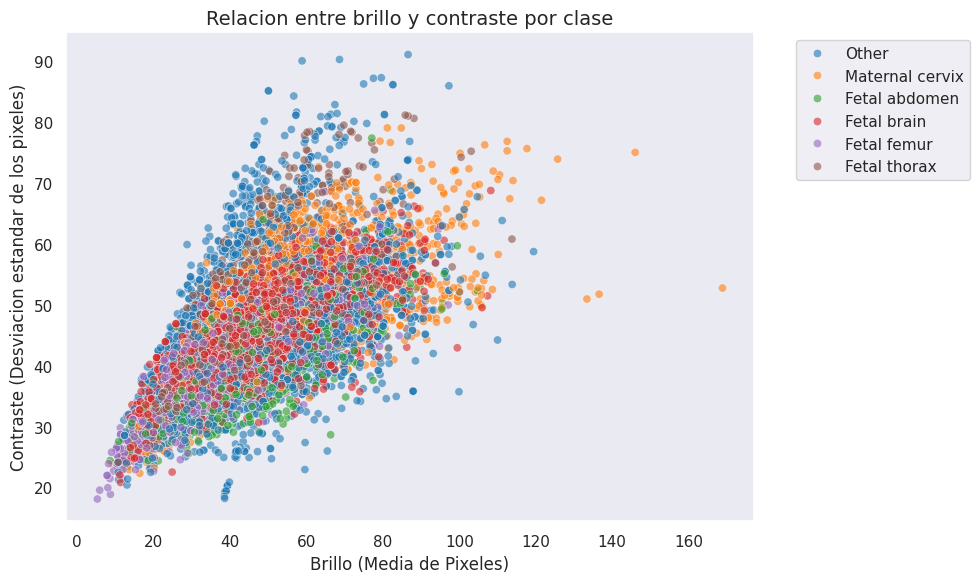

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_copy, x='brillo', y='contraste',hue='Plane', alpha=0.6 , palette='tab10')
plt.title('Relacion entre brillo y contraste por clase', fontsize=14)
plt.xlabel('Brillo (Media de Pixeles)')
plt.ylabel('Contraste (Desviacion estandar de los pixeles)')
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

### Histograma de intensidad

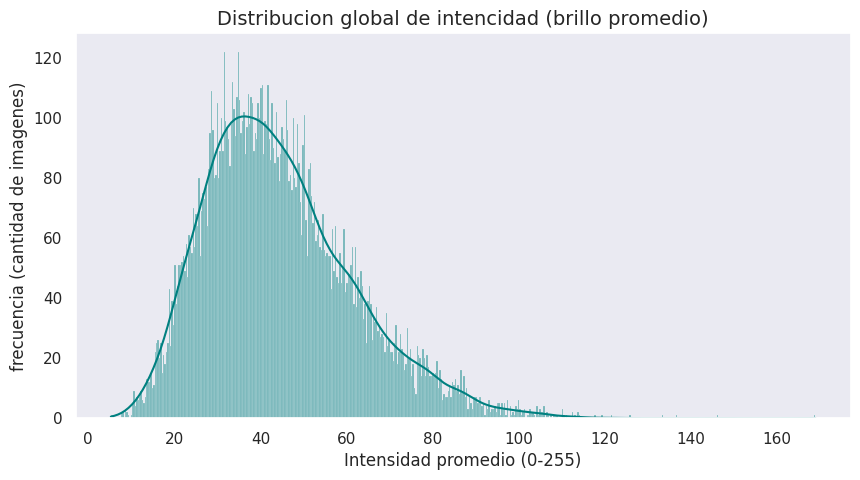

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df_copy['brillo'],bins=500,kde=True, color='teal')
plt.title('Distribucion global de intencidad (brillo promedio)', fontsize=14)
plt.xlabel('Intensidad promedio (0-255)')
plt.ylabel('frecuencia (cantidad de imagenes)')
plt.show()

/tmp/ipykernel_474/2710710010.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_copy,x='Plane', y='nitidez', palette='Set2')


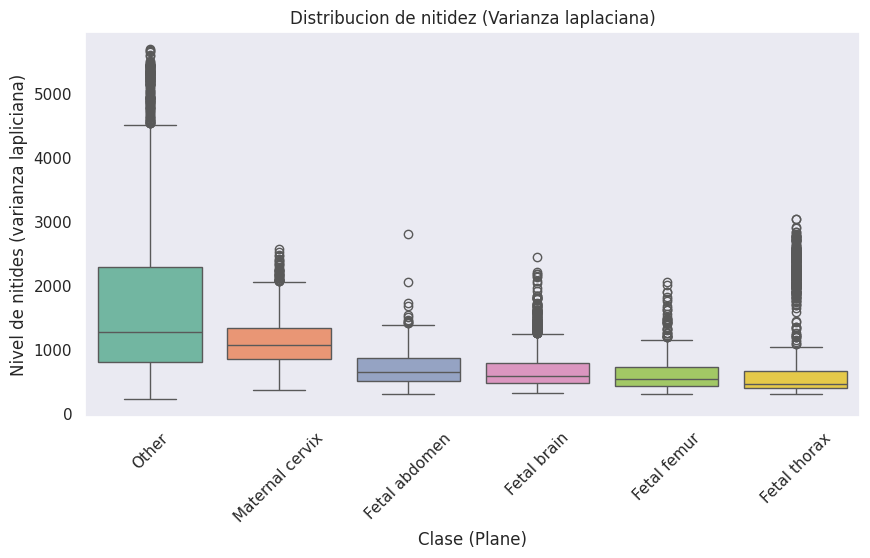

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_copy,x='Plane', y='nitidez', palette='Set2')
plt.title('Distribucion de nitidez (Varianza laplaciana)', fontsize=12)
plt.xlabel('Clase (Plane)')
plt.ylabel('Nivel de nitides (varianza lapliciana)')
#plt.yscale('log')#escala logaritmica para mejorar la visualizacion
plt.xticks(rotation=45)
plt.show()

# Parte 2. Preprocesamiento de los datos

Tareas: normalización, limpieza de duplicados, redimensionamiento, reducción de ruido y aumento de datos.

## Rutas y etiquetas

In [ ]:
X_paths = df['filepath'].to_numpy()
y = df['Plane'].to_numpy()

## Búsqueda y eliminación de imágenes duplicadas

In [ ]:

def encontrar_duplicados_visuales(paths):
    hashes_vistos = {}
    rutas_unicas = []
    rutas_duplicadas = []

    for filepath in paths:
        try:
            # Abrir la imagen y calcular su Hash Perceptual
            img = Image.open(filepath)
            hash_visual = imagehash.phash(img)

            if hash_visual in hashes_vistos:
                # ¡Es visualmente idéntica a una anterior!
                rutas_duplicadas.append(filepath)
            else:
                hashes_vistos[hash_visual] = filepath
                rutas_unicas.append(filepath)

        except Exception as e:
            print(f"Error leyendo {filepath}: {e}")

    print(f"Se encontraron {len(rutas_duplicadas)} imágenes visualmente duplicadas.")
    return rutas_unicas, rutas_duplicadas

In [ ]:
rutas_unicas, rutas_duplicadas = encontrar_duplicados_visuales(X_paths)

Se encontraron 1014 imágenes visualmente duplicadas.


In [ ]:
# @title Eliminacion de las imagenes de menor calidad  de clase mayoritaria apartir de la varianza lapiciana
clase_mayoritaria = 'Other'
df_unicas = df_copy[df_copy['filepath'].isin(rutas_unicas)].copy()
nitidez_others = df_unicas[df_unicas['Plane'] == clase_mayoritaria]['nitidez'].dropna()

# Definir un percentil límite (por ejemplo, el 15% de las imágenes con menor nitidez se consideran de baja calidad)
percentil_corte = 15
umbral_nitidez = np.percentile(nitidez_others, percentil_corte)

print(f"Umbral de nitidez (Laplaciana) para el percentil {percentil_corte}% en la clase '{clase_mayoritaria}': {umbral_nitidez:.2f}")
df_no_others = df_unicas[df_unicas['Plane'] != clase_mayoritaria]
df_others_filtrado = df_unicas[(df_unicas['Plane'] == clase_mayoritaria) & (df_unicas['nitidez'] >= umbral_nitidez)]
df_purificado = pd.concat([df_no_others, df_others_filtrado], ignore_index=True)

print(f"Imágenes únicas iniciales: {len(rutas_unicas)}")
rutas_unicas = df_purificado['filepath'].tolist()
print(f"Imágenes después de purificar '{clase_mayoritaria}' (eliminando el {percentil_corte}% inferior): {len(rutas_unicas)}")


Umbral de nitidez (Laplaciana) para el percentil 15% en la clase 'Other': 647.75
Imágenes únicas iniciales: 11386
Imágenes después de purificar 'Other' (eliminando el 15% inferior): 10843


In [ ]:
# Eliminación de duplicados: se conserva solo la primera aparición de cada imagen
# (se hace ANTES del split para evitar fuga de datos entre train y test)
print(f'Antes: {len(df)} imágenes')
df = df[df['filepath'].isin(rutas_unicas)].reset_index(drop=True)
X_paths = df['filepath'].to_numpy()
y = df['Plane'].to_numpy()
print(f'Después: {len(df)} imágenes únicas')

Antes: 12400 imágenes
Después: 10843 imágenes únicas


## División train/test, redimensionamiento y normalización

In [ ]:
X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    X_paths,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,

)

IMAGE_SIZE = (128, 128)


def cargar_imagenes(paths):
    imagenes = []
    rutas_validas = []

    for filepath in paths:
        imagen = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
        if imagen is None:
            print(f'No se pudo leer: {filepath}')
            continue

        imagen = cv2.resize(imagen, IMAGE_SIZE)
        imagenes.append(imagen.astype(np.float32) / 255.0)
        rutas_validas.append(filepath)

    return np.array(imagenes), np.array(rutas_validas)


X_train, train_paths_valid = cargar_imagenes(X_train_paths)
X_test, test_paths_valid = cargar_imagenes(X_test_paths)

# Mantener las etiquetas alineadas si alguna imagen no pudo leerse.
train_valid_mask = np.isin(X_train_paths, train_paths_valid)
test_valid_mask = np.isin(X_test_paths, test_paths_valid)
y_train = y_train[train_valid_mask]
y_test = y_test[test_valid_mask]

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')
print(f'Rango de píxeles: {X_train.min():.1f} - {X_train.max():.1f}')

X_train: (8674, 128, 128), y_train: (8674,)
X_test: (2169, 128, 128), y_test: (2169,)
Rango de píxeles: 0.0 - 1.0


In [ ]:
#@title Exportar Datasets csv de los conjuntos de entrenamiento y prueba
#@markdown Define la ruta de la carpeta donde quieres almacenar los archivos generados.

# Ruta para guardar los CSV (Puedes modificarla directamente aquí o desde los campos de formulario de Colab)
RUTA_DESTINO = "/content/drive/MyDrive/IA2/Proyecto/dataset" #@param {type:"string"}

destino_path = Path(RUTA_DESTINO)
destino_path.mkdir(parents=True, exist_ok=True)

# 1. Crear el DataFrame para el conjunto de entrenamiento
df_train = pd.DataFrame({
    'filepath': train_paths_valid,
    'Plane': y_train
})

# 2. Crear el DataFrame para el conjunto de testeo
df_test = pd.DataFrame({
    'filepath': test_paths_valid,
    'Plane': y_test
})

# Guardar en archivos CSV
train_csv_path = destino_path / 'fetal_planes_train.csv'
test_csv_path = destino_path / 'fetal_planes_test.csv'

df_train.to_csv(train_csv_path, index=False, sep=';')
df_test.to_csv(test_csv_path, index=False, sep=';')

print(f"¡Archivos guardados exitosamente!")
print(f"- Entrenamiento ({len(df_train)} registros): {train_csv_path}")
print(f"- Testeo ({len(df_test)} registros): {test_csv_path}")

¡Archivos guardados exitosamente!
- Entrenamiento (8674 registros): /content/drive/MyDrive/IA2/Proyecto/dataset/fetal_planes_train.csv
- Testeo (2169 registros): /content/drive/MyDrive/IA2/Proyecto/dataset/fetal_planes_test.csv
